# Stage 2 – Constrained Customer Selection
Owner: _name_

**Goal:** from the Stage 1 top 10, choose exactly 6 customers that maximise total expected net value

  value_i = predicted_probability_i × expected_deposit_value_i − contact_cost_i

subject to: exactly 6 selected, total contact cost ≤ 25, total capacity ≤ 22.

Plan: (1) build the candidate table, (2) solve exactly by checking every option (classical baseline), (3) write the problem as a QUBO, (4) solve it with two QAOA variants and compare to the exact answer. Code lives in `src/stage2.py`.

In [1]:
import sys, warnings; sys.path.append('../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, itertools
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector
from config import SEED, SHOTS, STAGE2_RESULTS
from stage2 import *
np.random.seed(SEED)

## 1. Candidate table (top 10 from Stage 1 + operational data)

In [2]:
cand, limits = load_candidates()
print(limits)
cand.round(3)

{'N': 10, 'K': 6, 'C': 25.0, 'H': 22.0}


,rank,customer_id,predicted_probability,contact_cost,expected_deposit_value,capacity_units,customer_segment,expected_net_value
0,1,C0031,0.428,2,13,1,D,3.567
1,2,C0079,0.385,3,24,3,A,6.231
2,3,C0183,0.282,2,14,3,B,1.942
3,4,C0081,0.262,4,17,1,C,0.457
4,5,C0318,0.249,3,21,3,A,2.232
5,6,C0208,0.233,4,21,3,D,0.891
6,7,C0338,0.218,2,18,2,A,1.926
7,8,C0059,0.206,3,27,3,C,2.562
8,9,C0265,0.206,4,23,4,D,0.738
9,10,C0170,0.198,1,22,1,C,3.350


## 2. Are the budget and capacity limits actually binding?
Worst case for each limit: the 6 most expensive (or most capacity-hungry) candidates.

In [3]:
constraints_are_redundant(cand, limits)

{'worst_cost': np.int64(21),
 'budget': 25.0,
 'budget_redundant': np.True_,
 'worst_capacity': np.int64(19),
 'capacity': 22.0,
 'capacity_redundant': np.True_}

**Finding:** even the 6 most expensive candidates cost 21 ≤ 25, and the 6 most capacity-hungry use 19 ≤ 22. So *every* choice of 6 from this top 10 satisfies both limits. The only constraint that matters is "exactly 6".

This is checked from the data, not assumed: if Stage 1 produced a different top 10, the check could fail, and the inequality constraints would then need slack variables in the QUBO (see section 4 notes).

## 3. Exact classical solution: check all C(10,6) = 210 selections

In [4]:
feasible, n_checked = brute_force(cand, limits)
print(f'checked {n_checked} selections, {len(feasible)} feasible')
best = feasible.iloc[0]
opt_bits = x_to_bitstring(best.x)
print('optimal selection:', cand.loc[best.x == 1, 'customer_id'].tolist())
feasible.drop(columns='x').head(5).round(3)

checked 210 selections, 210 feasible
optimal selection: ['C0031', 'C0079', 'C0183', 'C0318', 'C0059', 'C0170']


,n_selected,total_value,total_cost,total_capacity,feasible
0,6,19.885,14.0,14.0,True
1,6,19.869,14.0,13.0,True
2,6,19.579,13.0,13.0,True
3,6,19.249,13.0,13.0,True
4,6,18.834,16.0,14.0,True


Note how close #1 and #2 are (≈ 0.016 apart). They differ only in C0183 vs C0338, whose expected values are nearly equal. Small changes in Stage 1 probabilities could swap them, which is worth mentioning when discussing error propagation.

## 4. QUBO formulation
Binary variable x_i = 1 if candidate i is contacted. Minimise

  f(x) = −Σ v_i x_i + A (Σ x_i − 6)²

The penalty term is 0 when exactly 6 are chosen and grows quickly otherwise. **Choosing A:** changing the selection size by one changes the value term by at most max|v_i| ≈ 6.2, so any A larger than that makes every wrong-size selection worse than the best valid one. We use A = 1.5 × max|v_i| ≈ 9.3: big enough to be safe, not so big that the value differences become tiny compared to the penalty (which makes QAOA's job harder).

Budget/capacity would normally be added as A_C (Σ c_i x_i + s − 25)² with extra binary slack bits s (5 bits each here → 20 qubits total). Because section 2 proved they can never be violated, we leave them out and keep 10 qubits.

In [5]:
A = 1.5 * cand['expected_net_value'].abs().max()
Q, offset = build_qubo(cand, limits, A)
print('penalty A =', round(A, 3))

# Verify: the minimum of the QUBO over all 2^10 = 1024 bitstrings is the brute-force optimum
all_x = [np.array(b) for b in itertools.product([0, 1], repeat=len(cand))]
qvals = np.array([qubo_value(x, Q, offset) for x in all_x])
x_min = all_x[int(qvals.argmin())]
print('QUBO minimum equals brute-force optimum:', (x_min == best.x).all())

penalty A = 9.346
QUBO minimum equals brute-force optimum: True


### From QUBO to a quantum Hamiltonian
Substitute x_i = (1 − Z_i)/2. Each x_i becomes a Z on qubit i and each x_i x_j a ZZ pair. Measuring the circuit in state |x⟩ gives energy exactly f(x). **Bit order:** qubit i ↔ candidate row i; Qiskit prints qubit 0 as the rightmost character, so `bitstring_to_x` reverses strings.

In [6]:
H_qubo = qubo_to_ising(Q, offset)
# sanity check on three states
for x in [best.x, all_x[5], all_x[777]]:
    e = Statevector.from_label(x_to_bitstring(x)).expectation_value(H_qubo).real
    print(x_to_bitstring(x), round(e, 6), round(qubo_value(x, Q, offset), 6))

def normalise(H):
    c = H.coeffs.real
    m = np.abs(c[[l != 'I' * H.num_qubits for l in H.paulis.to_labels()]]).max()
    return (H / m).simplify()   # same minimiser, angles on a sensible scale

1010010111 -19.885184 -19.885184
1010000000 143.631586 143.631586
1001000011 22.311052 22.311052


## 5. QAOA
QAOA alternates two layers p times, with angles tuned by a classical optimiser (COBYLA, 5 random starts, exact statevector simulation):
- **cost layer** e^(−iγH): phases each bitstring by how good it is
- **mixer layer** e^(−iβM): moves amplitude between bitstrings

We compare two versions:

| | Start state | Mixer | How "exactly 6" is enforced |
|---|---|---|---|
| **Penalty QAOA** | all 1024 bitstrings equally (H on every qubit) | X on each qubit | penalty term in H |
| **XY QAOA** | Dicke state: all 210 valid selections equally | XX+YY between neighbours (swaps a 0 and a 1) | built into the circuit: the number of 1s never changes |

For XY QAOA the cost is just −Σ v_i x_i (no penalty needed). The Dicke state is prepared exactly here; on hardware it would need its own preparation circuit.

In [7]:
H_pen = normalise(H_qubo)
H_lin = normalise(linear_cost_hamiltonian(cand))
variants = {
    'penalty': dict(H=H_pen, mixer='x', init=Statevector.from_label('0' * len(cand))),
    'xy':      dict(H=H_lin, mixer='xy', init=dicke_state(len(cand), limits['K'])),
}
rows, runs = [], {}
for name, v in variants.items():
    for p in [1, 2, 3]:
        r = run_qaoa(v['H'], p, v['mixer'], v['init'], restarts=5, seed=SEED)
        counts = sample_qaoa(r, SHOTS, seed=SEED)
        runs[(name, p)] = (r, counts)
        feas_shots = {b: c for b, c in counts.items() if evaluate(bitstring_to_x(b), cand, limits)['feasible']}
        best_sampled = max(feas_shots, key=lambda b: evaluate(bitstring_to_x(b), cand, limits)['total_value'])
        rows.append(dict(variant=name, p=p, P_optimal=counts.get(opt_bits, 0) / SHOTS,
                         P_feasible=sum(feas_shots.values()) / SHOTS,
                         most_frequent_is_optimal=max(counts, key=counts.get) == opt_bits,
                         best_sampled_is_optimal=best_sampled == opt_bits,
                         depth=r['circuit'].decompose().depth()))
summary = pd.DataFrame(rows)
print(f'random guessing: P(optimal) = 1/1024 = {1/1024:.4f} (all bitstrings), 1/210 = {1/210:.4f} (valid only)')
summary.round(4)

random guessing: P(optimal) = 1/1024 = 0.0010 (all bitstrings), 1/210 = 0.0048 (valid only)


,variant,p,P_optimal,P_feasible,most_frequent_is_optimal,best_sampled_is_optimal,depth
0,penalty,1,0.0074,0.4708,False,True,54
1,penalty,2,0.0116,0.7649,False,True,86
2,penalty,3,0.0120,0.5746,False,True,118
3,xy,1,0.0548,1.0000,False,True,21
4,xy,2,0.0891,1.0000,False,True,42
5,xy,3,0.1023,1.0000,False,True,63


### Top measured bitstrings (best run: XY QAOA, p = 3)

In [8]:
r, counts = runs[('xy', 3)]
top = sorted(counts.items(), key=lambda kv: -kv[1])[:8]
pd.DataFrame([{'bitstring': b, 'shots': c, 'customers': cand.loc[bitstring_to_x(b) == 1, 'customer_id'].tolist(),
               'total_value': round(evaluate(bitstring_to_x(b), cand, limits)['total_value'], 3),
               'is_optimal': b == opt_bits} for b, c in top])

,bitstring,shots,customers,total_value,is_optimal
0,0011010111,1220,"[C0031, C0079, C0183, C0318, C0338, C0059]",18.461,False
1,1010010111,838,"[C0031, C0079, C0183, C0318, C0059, C0170]",19.885,True
2,1011010110,677,"[C0079, C0183, C0318, C0338, C0059, C0170]",18.244,False
3,1011010011,374,"[C0031, C0079, C0318, C0338, C0059, C0170]",19.869,False
4,0111010011,372,"[C0031, C0079, C0318, C0338, C0059, C0265]",17.257,False
5,1001010111,334,"[C0031, C0079, C0183, C0318, C0338, C0170]",19.249,False
6,0010011111,302,"[C0031, C0079, C0183, C0081, C0318, C0059]",16.992,False
7,0011011011,224,"[C0031, C0079, C0081, C0318, C0338, C0059]",16.976,False


β = [2.777 2.764 2.828]  γ = [1.232 0.597 3.426]


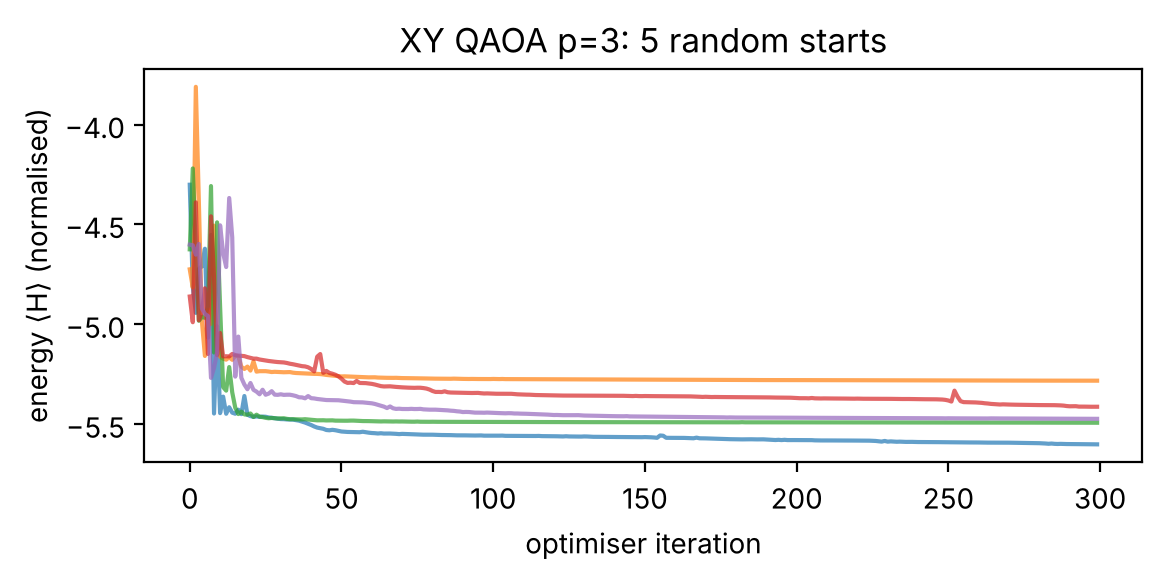

In [9]:
p_ = len(r['theta']) // 2   # Qiskit sorts parameters by name, so β comes before γ
print('β =', np.round(r['theta'][:p_], 3), ' γ =', np.round(r['theta'][p_:], 3))
fig, ax = plt.subplots(figsize=(6, 3))
for trace in r['history']:
    ax.plot(trace, alpha=0.7)
ax.set_xlabel('optimiser iteration'); ax.set_ylabel('energy ⟨H⟩ (normalised)'); ax.set_title('XY QAOA p=3: 5 random starts')
plt.tight_layout(); plt.show()

**Reading the results**
- Penalty QAOA wastes many shots on invalid selections (wrong number of customers); XY QAOA never does, because the circuit cannot change how many are selected.
- XY QAOA puts roughly 20× more probability on the optimum than random guessing among valid selections. The single most frequent bitstring is not always the optimum (the top few selections are within ~0.02–1.5 of each other), so, as is standard for QAOA, we take the **best-value bitstring among the samples** as the answer, and it matches brute force.
- With only 210 options, brute force is instant. QAOA is shown as a working method that would scale differently, not as a speed-up. No quantum advantage is claimed.

## 6. Final selection and save

In [10]:
r, counts = runs[('xy', 3)]
sampled = [b for b in counts if evaluate(bitstring_to_x(b), cand, limits)['feasible']]
qaoa_bits = max(sampled, key=lambda b: evaluate(bitstring_to_x(b), cand, limits)['total_value'])
x_final = bitstring_to_x(qaoa_bits)
assert (x_final == best.x).all(), 'QAOA answer differs from brute force: investigate before submitting'
ev = evaluate(x_final, cand, limits); assert ev['feasible']

out = cand.copy()
out['contact_decision'] = x_final
out['qubit_index'] = range(len(cand))
out.to_csv(STAGE2_RESULTS, index=False)
print('Selected:', out.loc[out.contact_decision == 1, 'customer_id'].tolist())
print(ev)
out[out.contact_decision == 1].round(3)

Selected: ['C0031', 'C0079', 'C0183', 'C0318', 'C0059', 'C0170']
{'n_selected': 6, 'total_value': 19.885183999622733, 'total_cost': 14.0, 'total_capacity': 14.0, 'feasible': True}


,rank,customer_id,predicted_probability,contact_cost,expected_deposit_value,capacity_units,customer_segment,expected_net_value,contact_decision,qubit_index
0,1,C0031,0.428,2,13,1,D,3.567,1,0
1,2,C0079,0.385,3,24,3,A,6.231,1,1
2,3,C0183,0.282,2,14,3,B,1.942,1,2
4,5,C0318,0.249,3,21,3,A,2.232,1,4
7,8,C0059,0.206,3,27,3,C,2.562,1,7
9,10,C0170,0.198,1,22,1,C,3.350,1,9


## 7. Extra fields required by the submission rules

In [11]:
top_bits = sorted(counts.items(), key=lambda kv: -kv[1])[:5]
out['selected_ids'] = ','.join(out.loc[out.contact_decision == 1, 'customer_id'])
out['budget_used'] = ev['total_cost']; out['budget_limit'] = limits['C']
out['capacity_used'] = ev['total_capacity']; out['capacity_limit'] = limits['H']
out['objective_value_qaoa'] = ev['total_value']
out['best_bitstring_qaoa'] = qaoa_bits            # Qiskit order: qubit 0 = rightmost character
out['top5_measured_bitstrings'] = ';'.join(f'{b}:{c}' for b, c in top_bits)
out['p_optimal_qaoa'] = counts.get(opt_bits, 0) / SHOTS
out['classical_optimum'] = best.total_value
out['optimality_gap'] = best.total_value - ev['total_value']
out['method'] = 'XY-mixer QAOA p=3, COBYLA 5 restarts, exact statevector, 8192 shots'
out.to_csv(STAGE2_RESULTS, index=False)
out[['customer_id', 'contact_decision', 'objective_value_qaoa', 'classical_optimum', 'optimality_gap']]

,customer_id,contact_decision,objective_value_qaoa,classical_optimum,optimality_gap
0,C0031,1,19.885184,19.885184,0.0
1,C0079,1,19.885184,19.885184,0.0
2,C0183,1,19.885184,19.885184,0.0
3,C0081,0,19.885184,19.885184,0.0
4,C0318,1,19.885184,19.885184,0.0
5,C0208,0,19.885184,19.885184,0.0
6,C0338,0,19.885184,19.885184,0.0
7,C0059,1,19.885184,19.885184,0.0
8,C0265,0,19.885184,19.885184,0.0
9,C0170,1,19.885184,19.885184,0.0
